MNIST Loaded Successfully
Unlabelled: 10000
Labelled: 1000
Test: 10000

Training RBM 1 (784 -> 500)
Epoch 1/3 | Loss: 0.0899
Epoch 2/3 | Loss: 0.0834
Epoch 3/3 | Loss: 0.0790

Training RBM 2 (500 -> 250)
Epoch 1/3 | Loss: 0.0115
Epoch 2/3 | Loss: 0.0099
Epoch 3/3 | Loss: 0.0091


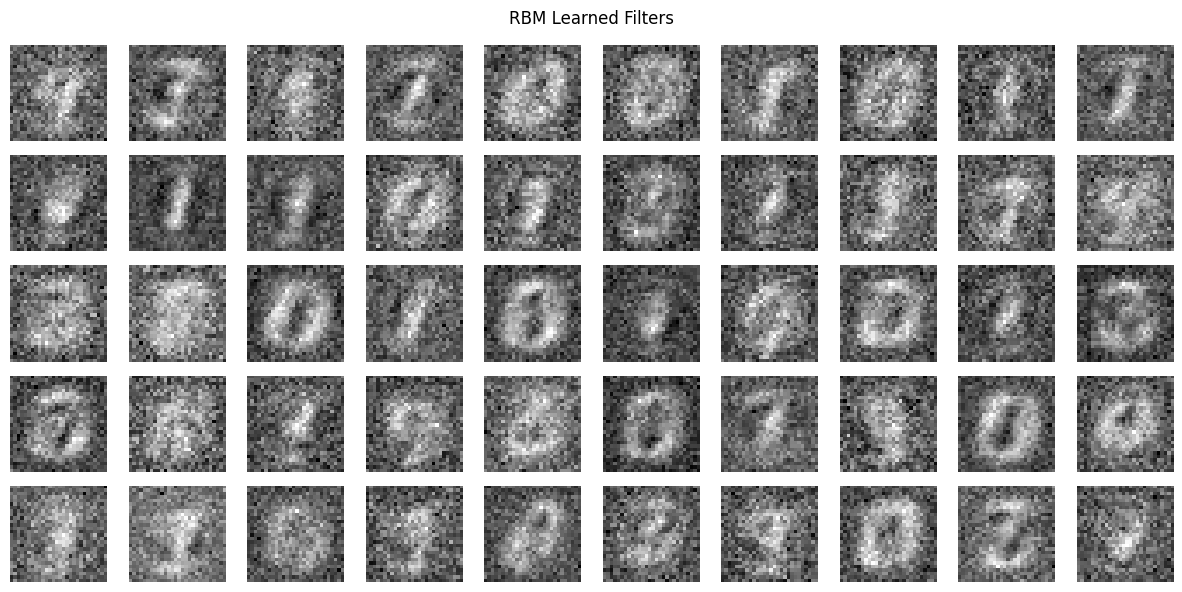


Fine-tuning pretrained DBN
Epoch 1/15
25/25 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - accuracy: 0.2637 - loss: 2.1214 - val_accuracy: 0.3450 - val_loss: 1.8995
Epoch 2/15
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.4675 - loss: 1.6069 - val_accuracy: 0.6600 - val_loss: 1.3702
Epoch 3/15
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.6413 - loss: 1.1306 - val_accuracy: 0.7650 - val_loss: 0.9950
Epoch 4/15
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.7425 - loss: 0.8150 - val_accuracy: 0.7900 - val_loss: 0.7875
Epoch 5/15
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.8238 - loss: 0.6170 - val_accuracy: 0.8250 - val_loss: 0.6752
Epoch 6/15
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.8675 - loss: 0.4848 - val_accuracy: 0.8450 - val_loss: 0.6137
Epoch 7/15
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.8988 - loss: 0.3953 - val_accuracy: 0.8350 - val_loss: 0.5744
Epoch 8/15
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.9125 - loss: 0.3313 - val

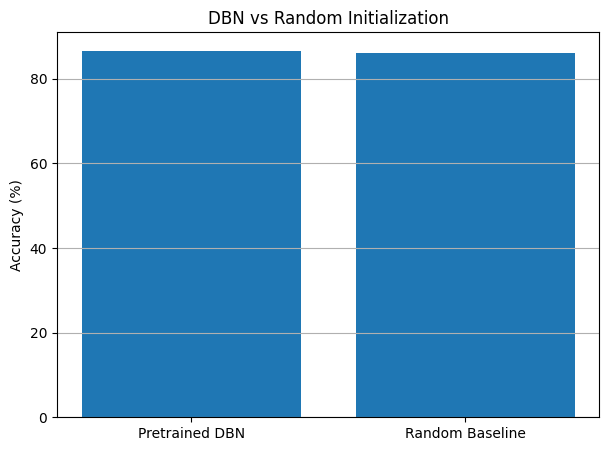

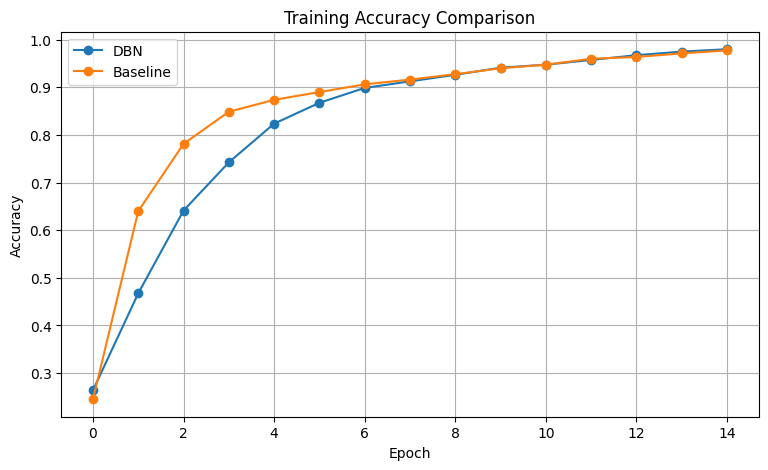


Generating t-SNE visualization...


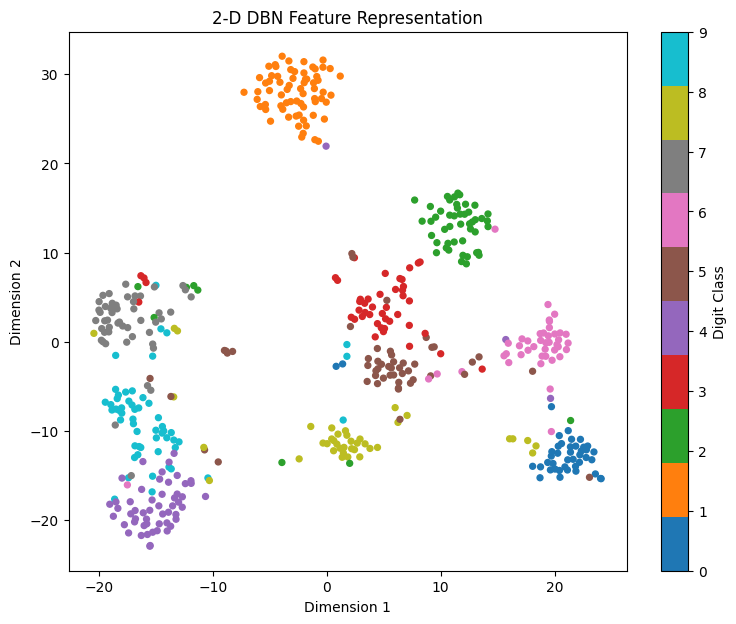

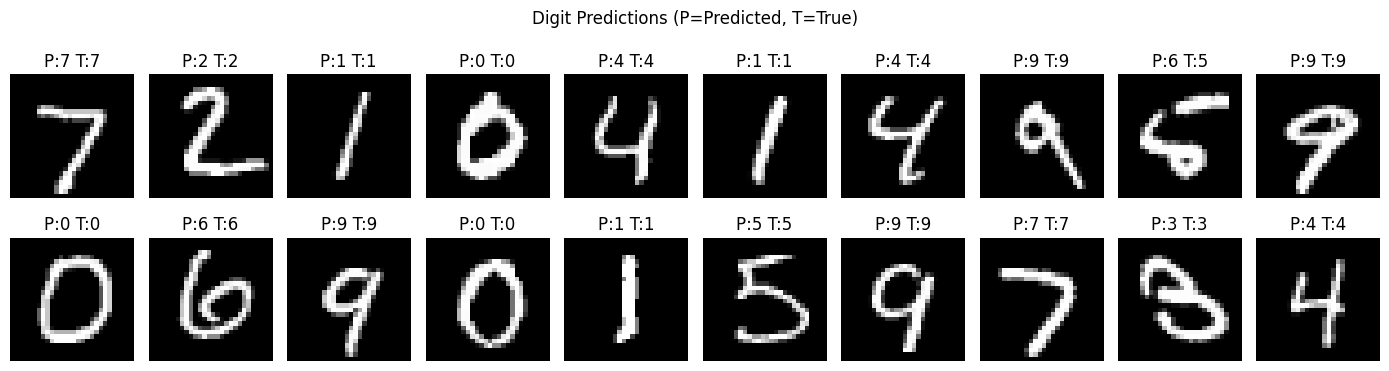


EXPERIMENT 27 COMPLETED
DBN Accuracy      : 86.68%
Baseline Accuracy : 86.02%
DBN performed better in this run.


In [16]:

# EXPERIMENT 27: DEEP BELIEF NETWORK REPRESENTATION LEARNING
# CLEAN KERAS 3 VERSION

!pip -q install tensorflow scikit-learn matplotlib

import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from sklearn.manifold import TSNE

np.random.seed(42)
tf.random.set_seed(42)

# ===================== 1. DATASET =====================
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()

x_train = x_train.astype(np.float32) / 255.0
x_test = x_test.astype(np.float32) / 255.0

x_train_flat = x_train.reshape(-1, 784)
x_test_flat = x_test.reshape(-1, 784)

x_train_binary = (x_train_flat > 0.5).astype(np.float32)

x_labelled = x_train_flat[:1000]
y_labelled = y_train[:1000]
x_unlabelled = x_train_binary[1000:11000]

print("MNIST Loaded Successfully")
print("Unlabelled:", len(x_unlabelled))
print("Labelled:", len(x_labelled))
print("Test:", len(x_test_flat))

# ===================== 2. RBM CLASS =====================
class RBM:
    def __init__(self, n_visible, n_hidden, lr=0.01):
        self.W = np.random.normal(
            0, 0.01, (n_visible, n_hidden)
        ).astype(np.float32)

        self.vb = np.zeros(n_visible, dtype=np.float32)
        self.hb = np.zeros(n_hidden, dtype=np.float32)
        self.lr = lr

    def sigmoid(self, x):
        x = np.clip(x, -30, 30)
        return 1 / (1 + np.exp(-x))

    def hidden_prob(self, v):
        return self.sigmoid(v @ self.W + self.hb)

    def visible_prob(self, h):
        return self.sigmoid(h @ self.W.T + self.vb)

    def sample(self, p):
        return (np.random.rand(*p.shape) < p).astype(np.float32)

    def train_batch(self, batch, k=1):
        # Positive phase
        ph0 = self.hidden_prob(batch)
        h = self.sample(ph0)

        # Negative phase
        for _ in range(k):
            pv = self.visible_prob(h)
            v1 = self.sample(pv)
            ph1 = self.hidden_prob(v1)
            h = self.sample(ph1)

        # Contrastive Divergence
        n = len(batch)

        self.W += self.lr * (batch.T @ ph0 - v1.T @ ph1) / n
        self.vb += self.lr * np.mean(batch - v1, axis=0)
        self.hb += self.lr * np.mean(ph0 - ph1, axis=0)

        reconstruction = self.visible_prob(ph0)
        return np.mean((batch - reconstruction) ** 2)

    def train(self, data, epochs=3, batch_size=128, k=1):
        losses = []

        for epoch in range(epochs):
            indices = np.random.permutation(len(data))
            batch_losses = []

            for start in range(0, len(data), batch_size):
                batch = data[indices[start:start+batch_size]]
                batch_losses.append(self.train_batch(batch, k))

            avg_loss = float(np.mean(batch_losses))
            losses.append(avg_loss)

            print(f"Epoch {epoch+1}/{epochs} | Loss: {avg_loss:.4f}")

        return losses

# ===================== 3. RBM 1 =====================
print("\nTraining RBM 1 (784 -> 500)")

rbm1 = RBM(784, 500, lr=0.01)
loss1 = rbm1.train(x_unlabelled, epochs=3, batch_size=128)

h1 = rbm1.hidden_prob(x_unlabelled)

# ===================== 4. RBM 2 =====================
print("\nTraining RBM 2 (500 -> 250)")

rbm2 = RBM(500, 250, lr=0.01)
loss2 = rbm2.train(h1, epochs=3, batch_size=128)

# ===================== 5. FILTER VISUALIZATION =====================
fig, axes = plt.subplots(5, 10, figsize=(12, 6))

filters = rbm1.W.T[:50]

for i, ax in enumerate(axes.flat):
    ax.imshow(filters[i].reshape(28, 28), cmap="gray")
    ax.axis("off")

plt.suptitle("RBM Learned Filters")
plt.tight_layout()
plt.show()

# ===================== 6. BUILD DBN =====================
inp = tf.keras.Input(shape=(784,), name="input")

h_layer1 = tf.keras.layers.Dense(
    500, activation="sigmoid", name="hidden1"
)(inp)

h_layer2 = tf.keras.layers.Dense(
    250, activation="sigmoid", name="hidden2"
)(h_layer1)

out = tf.keras.layers.Dense(
    10, activation="softmax", name="output"
)(h_layer2)

dbn = tf.keras.Model(inp, out)

# Transfer pretrained RBM weights
dbn.get_layer("hidden1").set_weights([rbm1.W, rbm1.hb])
dbn.get_layer("hidden2").set_weights([rbm2.W, rbm2.hb])

dbn.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# ===================== 7. DBN FINE-TUNING =====================
print("\nFine-tuning pretrained DBN")

history_dbn = dbn.fit(
    x_labelled,
    y_labelled,
    epochs=15,
    batch_size=32,
    validation_split=0.2,
    verbose=1
)

# ===================== 8. BASELINE MODEL =====================
print("\nTraining random initialization baseline")

base_inp = tf.keras.Input(shape=(784,))
b1 = tf.keras.layers.Dense(500, activation="sigmoid")(base_inp)
b2 = tf.keras.layers.Dense(250, activation="sigmoid")(b1)
base_out = tf.keras.layers.Dense(10, activation="softmax")(b2)

baseline = tf.keras.Model(base_inp, base_out)

baseline.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

history_base = baseline.fit(
    x_labelled,
    y_labelled,
    epochs=15,
    batch_size=32,
    validation_split=0.2,
    verbose=1
)

# ===================== 9. TEST EVALUATION =====================
dbn_loss, dbn_acc = dbn.evaluate(x_test_flat, y_test, verbose=0)
base_loss, base_acc = baseline.evaluate(x_test_flat, y_test, verbose=0)

print("\n========== TEST RESULTS ==========")
print(f"DBN Accuracy      : {dbn_acc*100:.2f}%")
print(f"Baseline Accuracy : {base_acc*100:.2f}%")
print(f"DBN Loss         : {dbn_loss:.4f}")
print(f"Baseline Loss    : {base_loss:.4f}")

# ===================== 10. ACCURACY GRAPH =====================
plt.figure(figsize=(7, 5))
plt.bar(["Pretrained DBN", "Random Baseline"],
        [dbn_acc*100, base_acc*100])
plt.ylabel("Accuracy (%)")
plt.title("DBN vs Random Initialization")
plt.grid(axis="y")
plt.show()

# ===================== 11. TRAINING GRAPH =====================
plt.figure(figsize=(9, 5))
plt.plot(history_dbn.history["accuracy"], marker="o", label="DBN")
plt.plot(history_base.history["accuracy"], marker="o", label="Baseline")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training Accuracy Comparison")
plt.legend()
plt.grid()
plt.show()

# ===================== 12. t-SNE VISUALIZATION =====================
print("\nGenerating t-SNE visualization...")

visual_count = 500
x_visual = x_test_flat[:visual_count]
y_visual = y_test[:visual_count]

# Build feature extractor directly from functional tensors
feature_model = tf.keras.Model(inputs=inp, outputs=h_layer2)

features = feature_model.predict(x_visual, verbose=0)

tsne = TSNE(
    n_components=2,
    random_state=42,
    perplexity=30,
    init="pca",
    learning_rate="auto"
)

features_2d = tsne.fit_transform(features)

plt.figure(figsize=(9, 7))
scatter = plt.scatter(
    features_2d[:, 0],
    features_2d[:, 1],
    c=y_visual,
    cmap="tab10",
    s=18
)
plt.colorbar(scatter, label="Digit Class")
plt.title("2-D DBN Feature Representation")
plt.xlabel("Dimension 1")
plt.ylabel("Dimension 2")
plt.show()

# ===================== 13. PREDICTIONS =====================
pred = np.argmax(dbn.predict(x_test_flat[:20], verbose=0), axis=1)

fig, axes = plt.subplots(2, 10, figsize=(14, 4))

for i, ax in enumerate(axes.flat):
    ax.imshow(x_test[i], cmap="gray")
    ax.set_title(f"P:{pred[i]} T:{y_test[i]}")
    ax.axis("off")

plt.suptitle("Digit Predictions (P=Predicted, T=True)")
plt.tight_layout()
plt.show()

# ===================== 14. FINAL RESULT =====================
print("\n================================")
print("EXPERIMENT 27 COMPLETED")
print("================================")
print(f"DBN Accuracy      : {dbn_acc*100:.2f}%")
print(f"Baseline Accuracy : {base_acc*100:.2f}%")

if dbn_acc > base_acc:
    print("DBN performed better in this run.")
else:
    print("Baseline performed better in this run.")
